#%% md
# Online Retail Sales Analysis

In [ ]:
# Setup (run once): install the packages this notebook needs
%pip install pandas matplotlib plotly ipywidgets openpyxl nbformat

How does revenue change each month?
Which 10 products generate the most revenue?
How much does a customer typically spend per order?
How does spending differ across key countries?

#%% md
## Data quality

In [29]:
import pandas as pd
df = pd.read_excel("/Users/juma/Desktop/dATA-VIS-CA2/Online-Retail.xlsx")
print(df.head())             
print(df.shape)              
df.info()                    
print(df.isna().sum())       
print(df.duplicated().sum())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
(541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------      

Shape: 541,909 rows × 8 columns. Each row is one line item on an invoice.
Dtypes: All fine. InvoiceDate is already a datetime. CustomerID is float64 
Missing values:
Description: 1,454 missing (0.3%). Minor.
CustomerID: 135,080 missing (about 25%).
Duplicates: 5,268 fully identical rows (about 1%). 

Quantity: min -80,995, max 80,995. That's one huge order and its cancellation (the famous pair in this dataset). The median is 3, so these are extreme outliers.
UnitPrice: min -11,062.06 is not a real price, it's a bad-debt adjustment. Max 38,970 is likely a manual/AMAZONFEE-type entry, not a product.
10,624 rows with negative Quantity (returns, cancellations, write-offs).
2,517 rows with UnitPrice <= 0 (free items, adjustments).
9,288 rows on C invoices (cancellations). Note 10,624 > 9,288, so about 1,300 negative-quantity rows are not C invoices.


#%% md
## Cleaning

In [3]:
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print("Negative quantities:", (df['Quantity'] < 0).sum())
print("Zero or negative prices:", (df['UnitPrice'] <= 0).sum())
print("Cancelled invoices:", df['InvoiceNo'].astype(str).str.startswith('C').sum())

# 2. Convert the invoice date
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# 3. Clean (print the shape after each step)
clean = df.drop_duplicates()
print("After duplicates:", clean.shape)

# Cancelled invoices start with C
clean = clean[~clean['InvoiceNo'].astype(str).str.startswith('C')]
print("After cancellations:", clean.shape)

# Negative or zero quantity
clean = clean[clean['Quantity'] > 0]
print("After quantity check:", clean.shape)

# Invalid prices
clean = clean[clean['UnitPrice'] > 0]
print("After price check:", clean.shape)

# Non-product codes (postage, fees, manual entries)
codes = ['POST', 'D', 'M', 'BANK CHARGES', 'AMAZONFEE', 'DOT', 'CRUK', 'S', 'B']
clean = clean[~clean['StockCode'].isin(codes)]
print("After non-product codes:", clean.shape)

# 4. New columns
clean['Revenue'] = clean['Quantity'] * clean['UnitPrice']
clean['Month'] = clean['InvoiceDate'].dt.to_period('M').astype(str)

# 5. Final check
print(clean.shape)
print(clean[['Quantity', 'UnitPrice', 'Revenue']].describe())

(541909, 8)
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Duplicates: 5268
Negative quantities: 10624
Zero or negative prices: 2517
Cancelled invoices: 9288
After duplicates: (536641, 8)
After cancellations: (527390, 8)
After quantity check: (526054, 8)
After price check: (524878, 8)
After non-product codes: (522713, 8)
(522713, 10)
            Quantity      UnitPrice        Revenue
count  522713.000000  522713.000000  522713.000000
mean       10.639802       3.287619      19.618718
std       156.568305       4.464488     269.893940
min         1.000000       0.001000       0.001000
25%         1

In total I removed 19,196 rows (3.5%), so most of the data is kept. Cancellations are the biggest group after duplicates.

                removed          left
Start		                     541,909
Duplicates	    5,268	         536,641
Cancellations(C)9,251	         527,390
Quantity <= 0	1,336	         526,054
Price <= 0	    1,176	         524,878
Non-product codes2,165	         522,713


In [4]:
print(clean.nlargest(5, 'Quantity')[['InvoiceNo', 'Description', 'Quantity', 'UnitPrice', 'InvoiceDate']])

       InvoiceNo                        Description  Quantity  UnitPrice  \
540421    581483        PAPER CRAFT , LITTLE BIRDIE     80995       2.08   
61619     541431     MEDIUM CERAMIC TOP STORAGE JAR     74215       1.04   
421632    573008  WORLD WAR 2 GLIDERS ASSTD DESIGNS      4800       0.21   
206121    554868               SMALL POPCORN HOLDER      4300       0.72   
97432     544612              EMPIRE DESIGN ROSETTE      3906       0.82   

               InvoiceDate  
540421 2011-12-09 09:15:00  
61619  2011-01-18 10:01:00  
421632 2011-10-27 12:26:00  
206121 2011-05-27 10:52:00  
97432  2011-02-22 10:43:00  


Two very large orders 74,215 and 80,995 units

In [32]:
print(df[df['Quantity'].abs() > 70000][['InvoiceNo', 'Description', 'Quantity', 'InvoiceDate']])

       InvoiceNo                     Description  Quantity         InvoiceDate
61619     541431  MEDIUM CERAMIC TOP STORAGE JAR     74215 2011-01-18 10:01:00
61624    C541433  MEDIUM CERAMIC TOP STORAGE JAR    -74215 2011-01-18 10:17:00
540421    581483     PAPER CRAFT , LITTLE BIRDIE     80995 2011-12-09 09:15:00
540422   C581484     PAPER CRAFT , LITTLE BIRDIE    -80995 2011-12-09 09:27:00


both bulk orders were cancelled within about 15 minutes by a C invoice with the exact same quantity, so removing them is justified.
541431 → C541433 (74,215 jars, 18 Jan 2011)
581483 → C581484 (80,995 paper craft items, 9 Dec 2011)


In [33]:
print(clean[clean['UnitPrice'] < 0.1][['Description', 'UnitPrice']].head(10))
print((clean['UnitPrice'] < 0.1).sum())

                                Description  UnitPrice
14788        PORCELAIN BUDAH INCENSE HOLDER      0.070
91772   ESSENTIAL BALM 3.5g TIN IN ENVELOPE      0.060
112953       BLUE STONES ON WIRE FOR CANDLE      0.080
157195           PADS TO MATCH ALL CUSHIONS      0.001
170361       PORCELAIN BUDAH INCENSE HOLDER      0.070
170392  SMALL FOLDING SCISSOR(POINTED EDGE)      0.080
170957          PAPER POCKET TRAVELING FAN       0.070
177435       BLUE STONES ON WIRE FOR CANDLE      0.080
195806       BLUE STONES ON WIRE FOR CANDLE      0.080
210605          PAPER POCKET TRAVELING FAN       0.070
235


In [34]:
# Remove the two cancelled bulk orders
cancelled_bulk = ['541431', '581483']
clean = clean[~clean['InvoiceNo'].astype(str).isin(cancelled_bulk)]
print("After removing 2 cancelled bulk orders:", clean.shape)

After removing 2 cancelled bulk orders: (522711, 12)


Two very large orders (74,215 and 80,995 units) were removed because each was cancelled the same day, so keeping them would overstate revenue

#%% md
## Exploratory analysis

In [35]:
import matplotlib.pyplot as plt

# Order value = total revenue of each invoice
order_values = clean.groupby('InvoiceNo')['Revenue'].sum()

print("Total sales:", round(clean['Revenue'].sum(), 2))
print("Number of orders:", clean['InvoiceNo'].nunique())
print("Number of customers:", clean['CustomerID'].nunique())
print("Mean order value:", round(order_values.mean(), 2))
print("Median order value:", round(order_values.median(), 2))

Total sales: 10009305.48
Number of orders: 19774
Number of customers: 4333
Mean order value: 506.19
Median order value: 302.32


The mean is higher than the median because a few very large orders pull it up

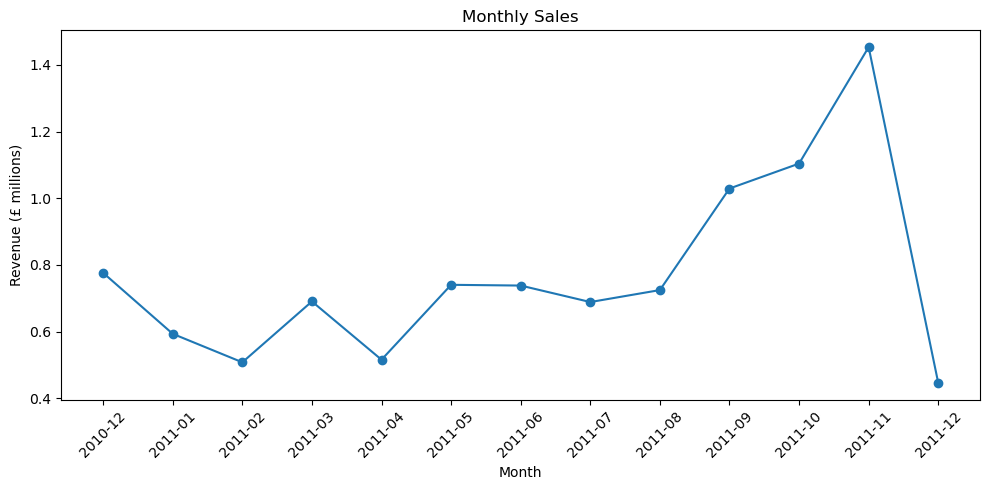

In [36]:
1. #Sales over time (monthly)
monthly = clean.groupby('Month')['Revenue'].sum() / 1_000_000
plt.figure(figsize=(10, 5))
plt.plot(monthly.index, monthly.values, marker='o')
plt.title('Monthly Sales')
plt.xlabel('Month')
plt.ylabel('Revenue (£ millions)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('monthly_sales.png')
plt.show()

Sales are flat at roughly £500k to £750k from Dec 2010 to Aug 2011, then climb from September to a peak of about £1.45M in November 2011 (consistent with Christmas demand, but the data shows timing, not cause).
December 2011 (about £450k) is not a real drop. The data stops on 9 Dec, so it's a partial month. 


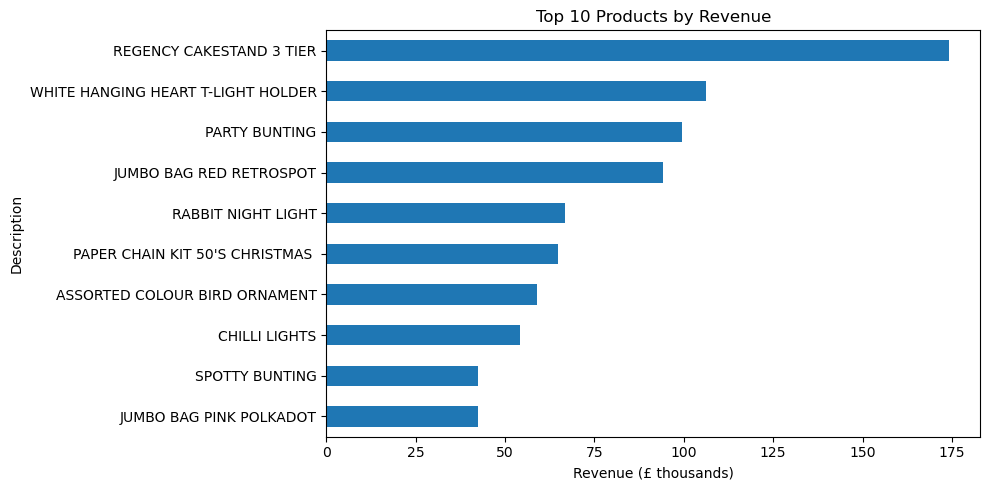

In [37]:
# 2. Top 10 products by revenue
top_products = clean.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(10) / 1000
plt.figure(figsize=(10, 5))
top_products.sort_values().plot(kind='barh')
plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (£ thousands)')
plt.tight_layout()
plt.savefig('top_products.png')
plt.show()

The Regency 3 Tier Cakestand generated about £174,000, compared with about £106,000 for the White Hanging Heart T-Light Holder in second place. Horizontal bars make the gap easy to see and leave room for the product names.

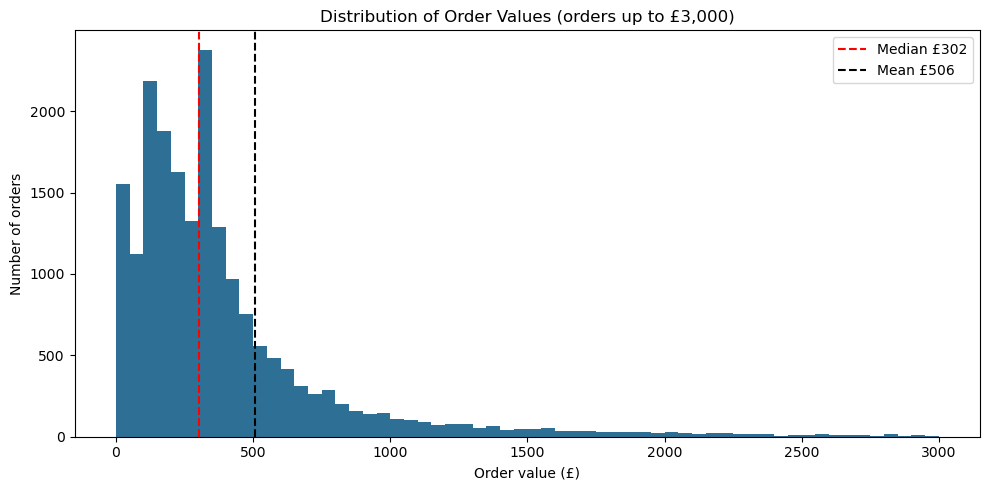

In [38]:
plt.figure(figsize=(10, 5))
plt.hist(order_values, bins=60, range=(0, 3000), color='#2E6F95')
plt.axvline(order_values.median(), color='red', linestyle='--', label=f'Median £{order_values.median():,.0f}')
plt.axvline(order_values.mean(), color='black', linestyle='--', label=f'Mean £{order_values.mean():,.0f}')
plt.title('Distribution of Order Values (orders up to £3,000)')
plt.xlabel('Order value (£)')
plt.ylabel('Number of orders')
plt.legend()
plt.tight_layout()
plt.savefig('order_value_hist.png')
plt.show()

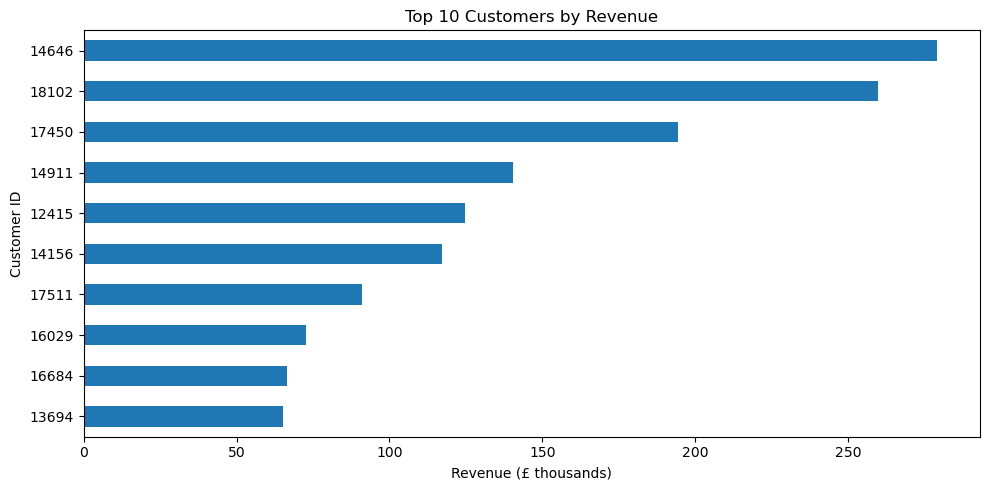

In [39]:
# 3. Top 10 customers by revenue (ignore missing CustomerID)
top_customers = clean.dropna(subset=['CustomerID']).groupby('CustomerID')['Revenue'].sum().sort_values(ascending=False).head(10) / 1000
top_customers.index = top_customers.index.astype(int).astype(str)
plt.figure(figsize=(10, 5))
top_customers.sort_values().plot(kind='barh')
plt.title('Top 10 Customers by Revenue')
plt.xlabel('Revenue (£ thousands)')
plt.ylabel('Customer ID')
plt.tight_layout()
plt.savefig('top_customers.png')
plt.show()

Customer 14646 spent about £280,000, followed by customer 18102 at about £260,000. Ranking customers by revenue helps the sales team identify its highest-spending accounts.

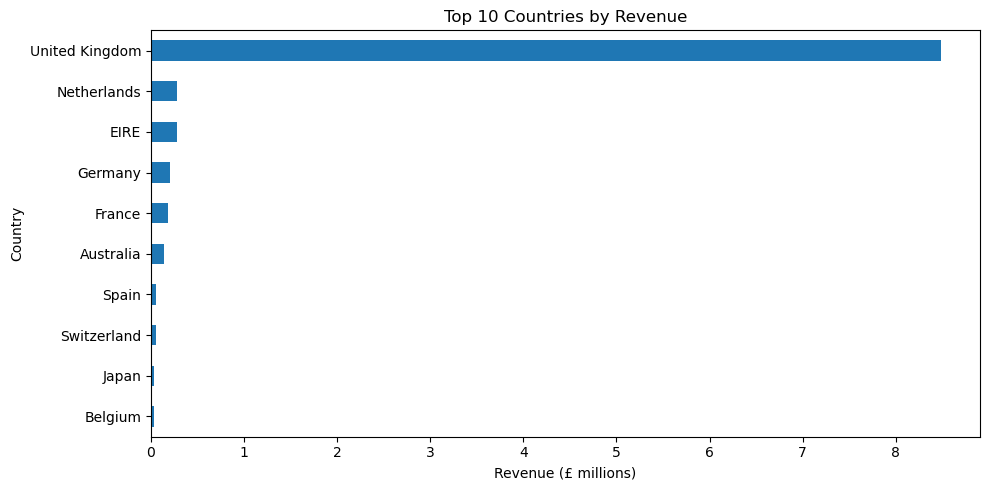

In [40]:
# 4. Top 10 countries by revenue
top_countries = clean.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(10) / 1_000_000
plt.figure(figsize=(10, 5))
top_countries.sort_values().plot(kind='barh')
plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue (£ millions)')
plt.ylabel('Country')
plt.tight_layout()
plt.savefig('top_countries.png')
plt.show()

The UK generated around £8.5 million, making it the retailer’s largest market. Using the same scale for every country shows how much larger UK sales were.

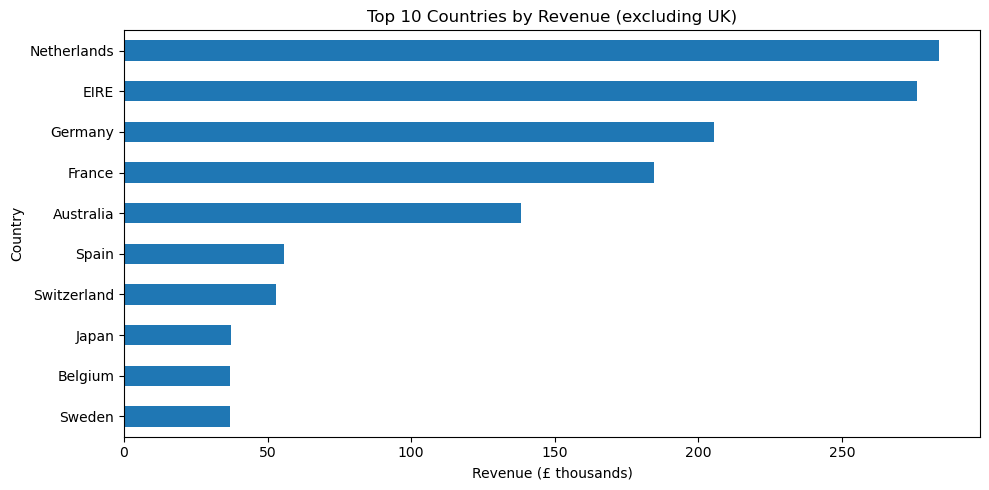

In [41]:
other = clean[clean['Country'] != 'United Kingdom'].groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(10) / 1000
plt.figure(figsize=(10, 5))
other.sort_values().plot(kind='barh')
plt.title('Top 10 Countries by Revenue (excluding UK)')
plt.xlabel('Revenue (£ thousands)')
plt.ylabel('Country')
plt.tight_layout()
plt.savefig('countries_no_uk.png')
plt.show()

The Netherlands and Ireland (listed as EIRE) were the two largest overseas markets, at roughly £284,000 and £276,000. Removing the UK from this second chart makes the small gap between them visible.

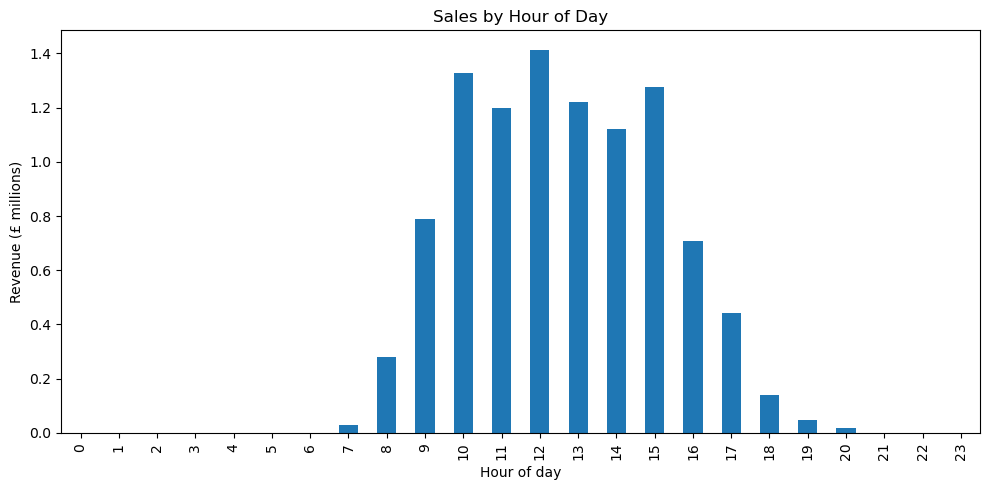

In [42]:
clean['Hour'] = clean['InvoiceDate'].dt.hour
hourly = clean.groupby('Hour')['Revenue'].sum().reindex(range(24), fill_value=0) / 1_000_000
plt.figure(figsize=(10, 5))
hourly.plot(kind='bar')
plt.title('Sales by Hour of Day')
plt.xlabel('Hour of day')
plt.ylabel('Revenue (£ millions)')
plt.tight_layout()
plt.savefig('hourly_sales.png')
plt.show()

This pattern is typical of a business-to-business wholesaler. Orders come in during working hours, not in the evening like consumer shopping. That fits the earlier findings: a few large trade customers, and a high mean order value compared to the median.

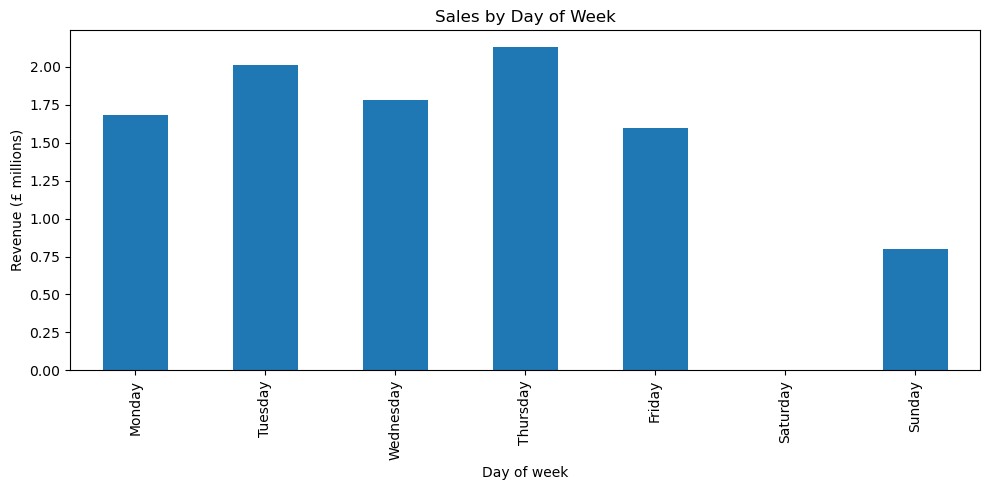

In [43]:
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
clean['DayOfWeek'] = clean['InvoiceDate'].dt.day_name()
daily = clean.groupby('DayOfWeek')['Revenue'].sum().reindex(days) / 1_000_000
plt.figure(figsize=(10, 5))
daily.plot(kind='bar')
plt.title('Sales by Day of Week')
plt.xlabel('Day of week')
plt.ylabel('Revenue (£ millions)')
plt.tight_layout()
plt.savefig('daily_sales.png')
plt.show()

Sales are concentrated Monday to Friday, with Thursday and Tuesday as peaks. This agrees with the hourly chart, which showed a working-hours pattern.

In [44]:
by_country = clean.groupby('Country').agg(
    Revenue=('Revenue', 'sum'),
    Orders=('InvoiceNo', 'nunique'))
by_country['AvgOrderValue'] = (by_country['Revenue'] / by_country['Orders']).round(2)
print(by_country[by_country['Orders'] >= 50].sort_values('AvgOrderValue', ascending=False).head(10))

                    Revenue  Orders  AvgOrderValue
Country                                           
Netherlands      283889.340      93        3052.57
Australia        138103.810      56        2466.14
Switzerland       53065.600      50        1061.31
EIRE             276090.860     284         972.15
Spain             55706.560      88         633.03
Portugal          26951.110      50         539.02
France           184679.000     383         482.19
United Kingdom  8480953.833   17899         473.82
Germany          205381.150     443         463.61
Belgium           36927.340      98         376.81


The UK generates about £8.5M, far more than any other country, but its average order value (£474) is low. The Netherlands and Australia have only 93 and 56 orders, yet their average orders are about £3,053 and £2,466. So the UK wins on volume, while a few export markets win on order size

#%% md
## Dashboard

I designed this dashboard for a retail manager who wants to see when sales were strongest, which products earned the most revenue, and how countries compare. The date range applies to all four charts. Selecting a country updates the three summary figures, the monthly sales line and the product ranking. The two country charts compare markets across the selected dates.

I used a line chart to show changes over time and horizontal bars to make product and country rankings easy to read. The manager can exclude the UK from the country comparisons because its sales are much higher than those of other markets.

In [45]:
df_clean = clean.copy()
df_clean['LineRevenue'] = df_clean['Revenue']

import pandas as pd
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display, clear_output

data = df_clean.copy()
data['Month'] = data['InvoiceDate'].dt.to_period('M').astype(str)

# Filters
countries = ['All countries'] + sorted(data['Country'].unique())
country_dd = widgets.Dropdown(options=countries, description='Country:')
start_dp = widgets.DatePicker(description='From:', value=data['InvoiceDate'].min().date())
end_dp = widgets.DatePicker(description='To:', value=data['InvoiceDate'].max().date())
exclude_uk = widgets.Checkbox(value=True, description='Exclude UK from comparison')
output = widgets.Output()

def update(change=None):
    with output:
        clear_output(wait=True)

        if start_dp.value is None or end_dp.value is None:
            print("Please pick a start and end date.")
            return

        # Filter by date
        start = pd.to_datetime(start_dp.value)
        end = pd.to_datetime(end_dp.value) + pd.Timedelta(days=1)
        by_date = data[(data['InvoiceDate'] >= start) & (data['InvoiceDate'] < end)]

        # Filter by country
        filtered = by_date
        if country_dd.value != 'All countries':
            filtered = by_date[by_date['Country'] == country_dd.value]

        if filtered.empty:
            print("No sales for this country in this date range.")
        else:
            total = filtered['LineRevenue'].sum()
            orders = filtered['InvoiceNo'].nunique()
            print(f"Total revenue: £{total:,.2f}")
            print(f"Orders: {orders:,}")
            print(f"Average order value: £{total / orders:,.2f}")

            monthly = filtered.groupby('Month')['LineRevenue'].sum().reset_index()
            px.line(monthly, x='Month', y='LineRevenue', markers=True,
                    title='Monthly Sales', labels={'LineRevenue': 'Revenue (£)'}).show()

            products = (filtered.groupby('Description')['LineRevenue'].sum()
                        .sort_values(ascending=False).head(10).sort_values().reset_index())
            px.bar(products, x='LineRevenue', y='Description', orientation='h',
                   title='Top 10 Products by Revenue', labels={'LineRevenue': 'Revenue (£)'}).show()

        # Country comparison: always runs if the date range has any sales
        if by_date.empty:
            print("No sales in this date range.")
            return

        # Country comparison (uses the date range only, so all countries stay visible)
        comp = by_date
        if exclude_uk.value:
            comp = comp[comp['Country'] != 'United Kingdom']
        by_country = comp.groupby('Country').agg(
            Revenue=('LineRevenue', 'sum'),
            Orders=('InvoiceNo', 'nunique'))
        by_country['AvgOrderValue'] = by_country['Revenue'] / by_country['Orders']
        by_country = by_country.sort_values('Revenue', ascending=False).head(10).reset_index()

        fig3 = px.bar(by_country.sort_values('Revenue'), x='Revenue', y='Country',
                      orientation='h', title='Country Comparison: Revenue',
                      labels={'Revenue': 'Revenue (£)'})
        fig3.show()

        fig4 = px.bar(by_country.sort_values('AvgOrderValue'), x='AvgOrderValue', y='Country',
                      orientation='h', title='Average Order Value in the Top 10 Countries by Revenue',
                      labels={'AvgOrderValue': 'Average order value (£)'})
        fig4.show()

# Re-run update whenever a filter changes
for w in [country_dd, start_dp, end_dp, exclude_uk]:
    w.observe(update, names='value')

display(widgets.VBox([widgets.HBox([country_dd, start_dp, end_dp]), exclude_uk]))
display(output)
update()

Output()